# 02 · Preprocessing and scale

Phase 3 of [project.md](../project.md). Questions this notebook answers:

1. What does each **preprocessing** step do (green channel, median, closing background, black top-hat, purple channel)?
2. **Why −b\*** is the purple-stain channel, seen in the colour space itself.
3. Does the **illumination correction** matter on BCCD, and when would it?
4. How does **granulometry** find the RBC radius `r`, and why is the raw pattern spectrum not enough?
5. Is `r` right? Against the BCCD boxes **and** when the image is zoomed (`scripts/check_scale.py`).

Prerequisites: `scripts/build_index.py`, `scripts/make_splits.py` and `scripts/check_scale.py`
(`make scale-check`) have been run. Only train/val images are used.

In [ ]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from skimage import color, filters

from bloodcells.config import load_config
from bloodcells.datasets import rbc_radius_per_image
from bloodcells.io_utils import load_image
from bloodcells.preprocessing import background_closing, denoise, green_channel, preprocess
from bloodcells.scale import estimate_scale, opening_by_disk, smooth_spectrum

cfg = load_config()
P = cfg["paths"]
FIG = P["results"] / "figures" / "preprocessing"
TAB = P["results"] / "tables"
FIG.mkdir(parents=True, exist_ok=True)

images = pd.read_csv(P["index"] / "bccd_images.csv")
boxes = pd.read_csv(P["index"] / "bccd_boxes.csv")
splits = json.loads(P["splits"].read_text(encoding="utf-8"))
image_path = images.set_index("image_id")["image_path"]
r_ref = rbc_radius_per_image(boxes)

rng = np.random.default_rng(cfg["seed"])
SAMPLE = sorted(rng.choice([i for i in splits["train"] if i in r_ref.index], 10, replace=False))
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 60
%config InlineBackend.figure_formats = ["jpeg"]
print("Sample:", ", ".join(SAMPLE))

Sample: BloodImage_00034, BloodImage_00037, BloodImage_00078, BloodImage_00176, BloodImage_00259, BloodImage_00283, BloodImage_00301, BloodImage_00347, BloodImage_00395, BloodImage_00403


## 1. Preprocessing step by step

`preprocess(img, cfg, r)` returns three channels:

| step | operation | why |
|------|-----------|-----|
| green | G channel of RGB | hemoglobin absorbs green light: RBCs are darkest there |
| denoise | median filter, disk radius 2 px | removes isolated noisy pixels, keeps edges sharp (a mean filter would blur them) |
| background | grayscale **closing** by a disk of radius 2.5 r (> WBC radius 1.9 r), at 1/4 resolution | cells are dark and smaller than the disk, so the closing erases them and keeps only the bright background |
| cells | **black top-hat** = closing − image, then contrast stretch | cells become bright on a flat, zero background whatever the lighting |
| purple | −b\* of CIE Lab, median, stretch | WBC nuclei and platelets bright, RBCs dark (section 2) |

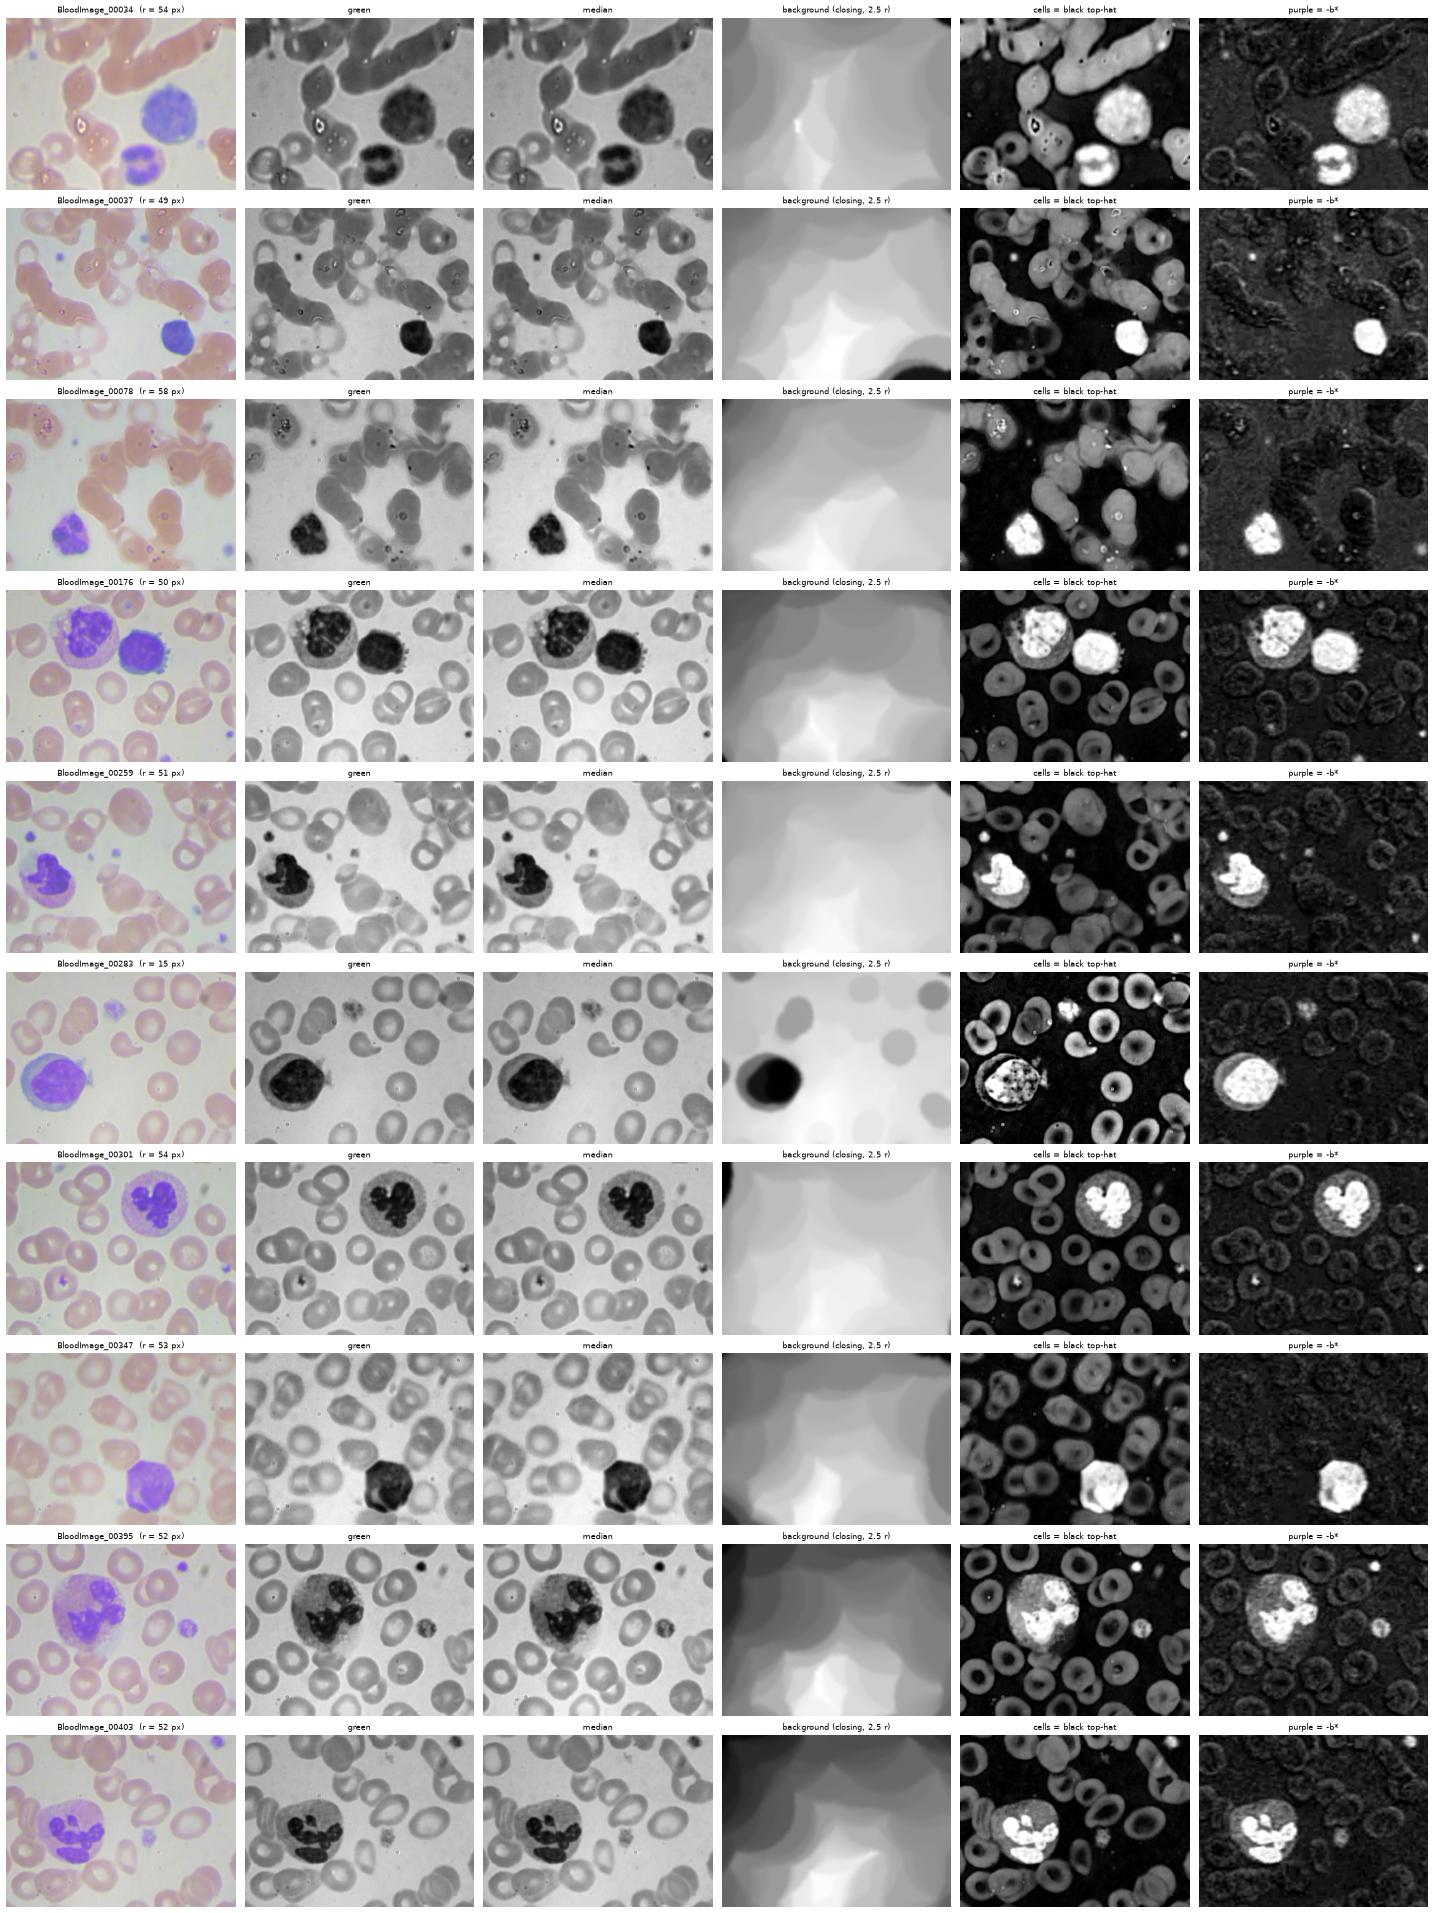

In [ ]:
def show_steps(image_id, axes=None):
    img = load_image(image_path[image_id])
    r = estimate_scale(img, cfg).r
    pre = preprocess(img, cfg, r)
    green = green_channel(img)
    bg = background_closing(pre["green"], cfg["preprocessing"]["tophat_r"] * r,
                            cfg["preprocessing"]["tophat_downsample"])
    panels = [(img, "RGB", None), (green, "green", "gray"), (pre["green"], "median", "gray"),
              (bg, f"background (closing, {cfg['preprocessing']['tophat_r']} r)", "gray"),
              (pre["cells"], "cells = black top-hat", "gray"), (pre["purple"], "purple = -b*", "gray")]
    if axes is None:
        _, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 3.2))
    for ax, (x, title, cmap) in zip(axes, panels):
        ax.imshow(x, cmap=cmap)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    axes[0].set_title(f"{image_id}  (r = {r:.0f} px)", fontsize=9)
    return axes


fig, axes = plt.subplots(len(SAMPLE), 6, figsize=(24, 3.2 * len(SAMPLE)))
for row, image_id in zip(axes, SAMPLE):
    show_steps(image_id, row)
fig.tight_layout()
fig.savefig(FIG / "preprocessing_steps.png", dpi=80)

## 2. Why −b\* for the purple stain

CIE Lab separates **lightness** L\* from two colour axes: a\* (green − / red +) and
b\* (blue − / yellow +). The background is almost neutral (a\*, b\* ≈ 0), RBCs are pink
(a\* > 0, b\* ≈ 0) and the Giemsa/Wright-stained nuclei and platelets are blue-violet,
i.e. **strongly negative b\***. So −b\* is high only on the purple stain, and it does not
depend on lightness: a pale nucleus and a dark one get similar values, while in the green
channel a dark RBC overlap looks like a nucleus. Notebook 01 measured the separation
(Fisher ratio, see `results/tables/channel_separability.csv`): −b\* is the best channel.

,fisher,WBC mean,RBC mean
channel,,,
-b* (Lab),7.617,42.797,-1.142
blue - green,7.454,90.444,2.948
saturation (HSV),4.828,0.445,0.124
a* (Lab),4.826,31.845,7.779
green (inverted),3.044,143.579,89.497
red - green,0.425,29.801,19.727


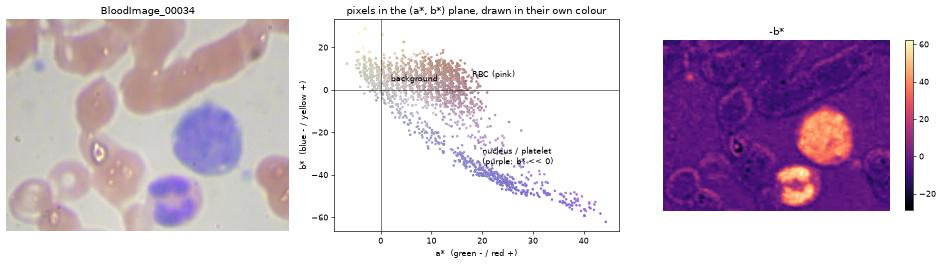

In [ ]:
image_id = SAMPLE[0]
img = load_image(image_path[image_id])
lab = color.rgb2lab(img)
idx = rng.choice(img.shape[0] * img.shape[1], 6000, replace=False)
a, b = lab[..., 1].ravel()[idx], lab[..., 2].ravel()[idx]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].imshow(img)
axes[0].set_title(image_id)
axes[1].scatter(a, b, c=img.reshape(-1, 3)[idx] / 255, s=4)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].axvline(0, color="k", lw=0.6)
axes[1].set_xlabel("a*  (green - / red +)")
axes[1].set_ylabel("b*  (blue - / yellow +)")
axes[1].set_title("pixels in the (a*, b*) plane, drawn in their own colour")
for text, xy in (("background", (2, 4)), ("RBC (pink)", (18, 6)), ("nucleus / platelet\n(purple: b* << 0)", (20, -35))):
    axes[1].annotate(text, xy, fontsize=9)
im = axes[2].imshow(-lab[..., 2], cmap="magma")
axes[2].set_title("-b*")
fig.colorbar(im, ax=axes[2], shrink=0.8)
for ax in (axes[0], axes[2]):
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "purple_channel_lab.png", dpi=80)
pd.read_csv(TAB / "channel_separability.csv", index_col=0)

## 3. Illumination correction

Notebook 01 found the BCCD lighting fairly uniform (one microscope, background p90
between 189 and 210). So the top-hat should change little on BCCD itself; it is there for
images with **vignetting** (darker corners) or a lighting gradient. Both cases are shown:

* the **real images**: Otsu on the raw green channel vs Otsu on the top-hat;
* the same images with a **synthetic vignetting** (brightness × 1 − s (d / d_max)²): the
  mask of each method is compared (Dice) with the mask that method gives on the clean image.

Three methods: Otsu on the raw green channel, on the black top-hat (closing − image), and on
the **relative** top-hat (closing − image) / closing. In transmitted light the image is
*illumination × transmittance*: a dim corner also has a lower cell contrast. Subtracting
the background removes the offset but not this contrast loss; dividing removes both
(flat-field correction). `tophat_relative: true` in `config.yaml`.

Clean images: agreement between methods (Dice)


,top-hat vs raw,relative vs top-hat
mean,0.922,0.989
min,0.793,0.969


Vignetted images: Dice between the mask on the clean and on the vignetted image


raw green        top-hat        relative top-hat       
              mean    min    mean    min             mean    min
strength                                                        
0.25         0.876  0.810   0.965  0.878            0.979  0.944
0.40         0.785  0.697   0.874  0.342            0.962  0.896

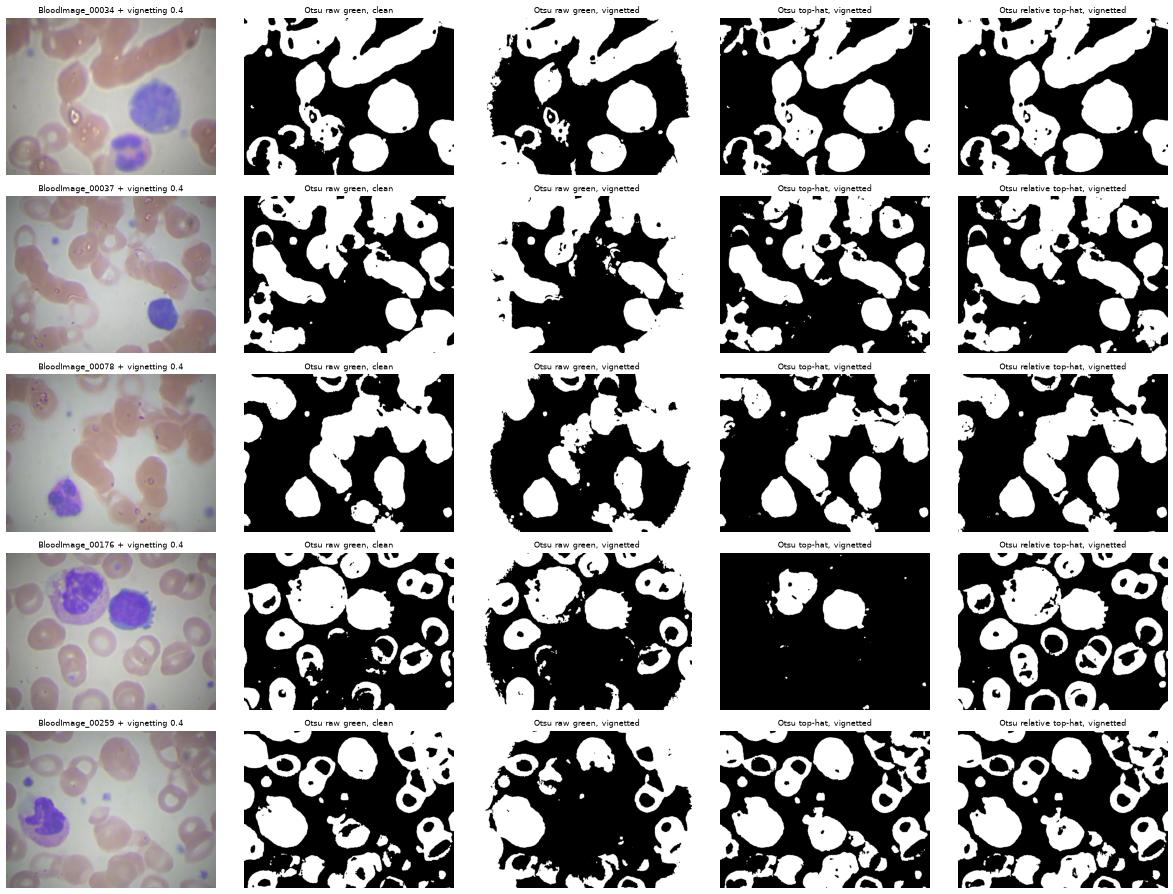

In [ ]:
def otsu_raw(img):
    g = denoise(green_channel(img), cfg["preprocessing"]["median_r"])
    return g < filters.threshold_otsu(g)


def otsu_tophat(img, r, relative=True):
    c = preprocess(img, {**cfg, "preprocessing": {**cfg["preprocessing"], "tophat_relative": relative}}, r)["cells"]
    return c > filters.threshold_otsu(c)


def vignette(img, strength=0.4):
    h, w = img.shape[:2]
    y, x = np.mgrid[:h, :w]
    d2 = ((y - h / 2) ** 2 + (x - w / 2) ** 2) / ((h / 2) ** 2 + (w / 2) ** 2)
    return (img * (1 - strength * d2)[..., None]).round().astype(np.uint8)


def dice(a, b):
    return 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)


METHODS = {"raw green": lambda im, r: otsu_raw(im),
           "top-hat": lambda im, r: otsu_tophat(im, r, relative=False),
           "relative top-hat": lambda im, r: otsu_tophat(im, r, relative=True)}
rows = []
fig, axes = plt.subplots(5, 5, figsize=(20, 15))
for n, image_id in enumerate(SAMPLE):
    img = load_image(image_path[image_id])
    r = estimate_scale(img, cfg).r
    clean = {m: f(img, r) for m, f in METHODS.items()}
    rows.append({"image_id": image_id, "strength": 0, "top-hat vs raw": dice(clean["top-hat"], clean["raw green"]),
                 "relative vs top-hat": dice(clean["relative top-hat"], clean["top-hat"])})
    for strength in (0.25, 0.4):
        dark = vignette(img, strength)
        masks = {m: f(dark, r) for m, f in METHODS.items()}
        rows.append({"image_id": image_id, "strength": strength,
                     **{m: dice(clean[m], masks[m]) for m in METHODS}})
        if n < 5 and strength == 0.4:
            panels = [(dark, f"{image_id} + vignetting 0.4"), (clean["raw green"], "Otsu raw green, clean")]
            panels += [(masks[m], f"Otsu {m}, vignetted") for m in METHODS]
            for ax, (x, title) in zip(axes[n], panels):
                ax.imshow(x, cmap=None if x.ndim == 3 else "gray")
                ax.set_title(title, fontsize=9)
                ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "illumination_correction.png", dpi=80)
illum = pd.DataFrame(rows)
print("Clean images: agreement between methods (Dice)")
display(illum[illum["strength"] == 0][["top-hat vs raw", "relative vs top-hat"]].agg(["mean", "min"]))
print("Vignetted images: Dice between the mask on the clean and on the vignetted image")
illum[illum["strength"] > 0].groupby("strength")[list(METHODS)].agg(["mean", "min"])

## 4. Granulometry: estimating the RBC radius

Openings by disks of growing radius k remove every object whose largest inscribed disk is
smaller than k. The **pattern spectrum** is the area removed between radius k and k + 1: it
has a peak at the inscribed radius of the most common objects, the RBCs.

The coarse mask (Otsu on the green channel + hole filling) needs no `r`: this is the
bootstrapping step. Each opening is computed with two Euclidean distance transforms, so any
radius costs the same (no large structuring element).

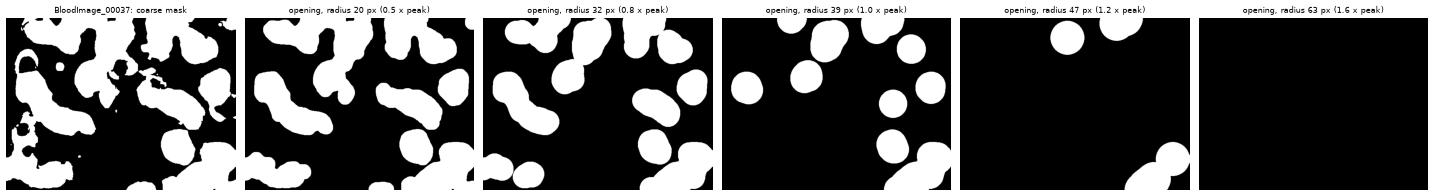

In [ ]:
image_id = SAMPLE[1]
img = load_image(image_path[image_id])
est = estimate_scale(img, cfg)
ks = [0.5, 0.8, 1.0, 1.2, 1.6]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(4 * (len(ks) + 1), 3.2))
axes[0].imshow(est.mask, cmap="gray")
axes[0].set_title(f"{image_id}: coarse mask", fontsize=9)
for ax, k in zip(axes[1:], ks):
    radius = k * est.r_inscribed
    ax.imshow(opening_by_disk(est.mask, radius), cmap="gray")
    ax.set_title(f"opening, radius {radius:.0f} px ({k} x peak)", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "granulometry_openings.png", dpi=80)

### Reading the spectrum

The raw spectrum is **area-weighted**: one WBC (radius ≈ 1.9 r, so ≈ 3.6× the area of an
RBC) or one clump of merged cells can outweigh ten RBCs, and the spectrum is spiky (each
object makes its own narrow peak). Two changes fix this (`smooth_spectrum`):

* **weighting** by 1/ρ (half-way between area and number of objects; weight 2, a pure count,
  lets small debris win);
* **smoothing with a constant width in log(ρ)** (σ = 0.08, i.e. ±8 %), so the smoothing is
  the same at any magnification.

The peak is the radius of the disk **inscribed** in a typical RBC. RBCs are slightly oval,
touch each other and the Otsu mask misses their pale rim, so it is smaller than the box radius
used to define the units of `config.yaml`: a single factor (`scale.calibration`, the median
ratio box radius / inscribed radius on **train**) converts one into the other.

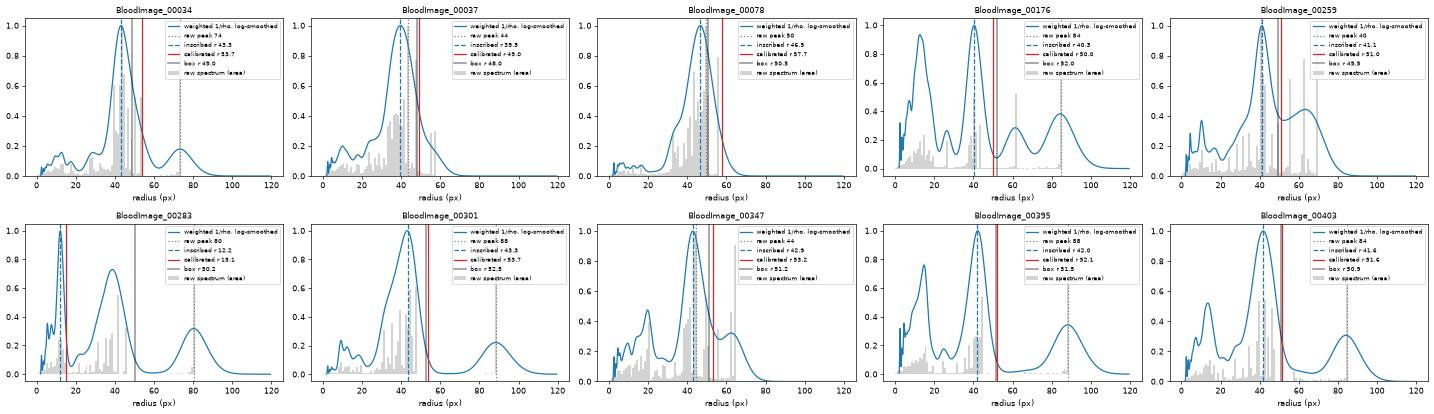

In [ ]:
def raw_peak(spectrum):
    return np.argmax(spectrum) + 0.5


fig, axes = plt.subplots(2, 5, figsize=(24, 7))
for ax, image_id in zip(axes.flat, SAMPLE):
    e = estimate_scale(load_image(image_path[image_id]), cfg)
    rho = e.radii - 0.5
    ax.bar(rho, e.spectrum / e.spectrum.max(), width=1, color="lightgray", label="raw spectrum (area)")
    ax.plot(e.grid, e.density / e.density.max(), color="tab:blue", label="weighted 1/rho, log-smoothed")
    ax.axvline(raw_peak(e.spectrum), color="gray", ls=":", label=f"raw peak {raw_peak(e.spectrum):.0f}")
    ax.axvline(e.r_inscribed, color="tab:blue", ls="--", label=f"inscribed r {e.r_inscribed:.1f}")
    ax.axvline(e.r, color="tab:red", label=f"calibrated r {e.r:.1f}")
    ax.axvline(r_ref[image_id], color="k", lw=2, alpha=0.4, label=f"box r {r_ref[image_id]:.1f}")
    ax.set_title(image_id, fontsize=9)
    ax.set_xlabel("radius (px)")
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "pattern_spectrum.png", dpi=80)

Effect of each change on the train/val images (inscribed radius re-estimated from the cached
spectra; calibration fitted on train each time, error measured on val).

In [ ]:
def spectrum_of(image_id):
    return estimate_scale(load_image(image_path[image_id]), cfg).spectrum


check = pd.read_csv(TAB / "scale_check.csv")
ids = check["image_id"].tolist()
spectra = dict(zip(ids, Parallel(n_jobs=-1)(delayed(spectrum_of)(i) for i in ids)))  # ~1 min
split_of = check.set_index("image_id")["split"]
train = [i for i in ids if split_of[i] == "train"]
val = [i for i in ids if split_of[i] == "val"]


def evaluate(weight, sigma_log):
    peaks = {}
    for i, s in spectra.items():
        grid, density = smooth_spectrum(s, weight, sigma_log, cfg["scale"]["r_min"])
        peaks[i] = grid[np.argmax(density)]
    r_in = pd.Series(peaks)
    c = float((r_ref[train] / r_in[train]).median())
    err = r_in[val] * c / r_ref[val] - 1
    return {"calibration": c, "val median |err|": err.abs().median(),
            "val within 15 %": (err.abs() < 0.15).mean(), "val > 30 %": int((err.abs() > 0.3).sum())}


variants = {
    "raw spectrum, little smoothing (old)": (0, 0.02),
    "area-weighted, log-smoothed": (0, 0.08),
    "1/rho weighted, log-smoothed (used)": (cfg["scale"]["weight"], cfg["scale"]["sigma_log"]),
    "count-weighted 1/rho^2, log-smoothed": (2, 0.08),
}
ablation = pd.DataFrame({name: evaluate(*p) for name, p in variants.items()}).T
ablation

,calibration,val median |err|,val within 15 %,val > 30 %
"raw spectrum, little smoothing (old)",1.036,0.206,0.351,25.0
"area-weighted, log-smoothed",1.199,0.050,0.811,12.0
"1/rho weighted, log-smoothed (used)",1.242,0.037,0.905,5.0
"count-weighted 1/rho^2, log-smoothed",20.551,0.055,0.851,10.0


## 5. Validation (`scripts/check_scale.py`)

**Box check.** Estimated `r` vs the per-image box radius. Careful: BCCD has a single
magnification, so the box radius barely varies (std ≈ 3 px around 52 px): a *constant* guess
would score well here too. This check shows the estimate is unbiased, not that it adapts.

**Zoom check.** The whole image is rescaled by 0.5 to 2: the estimate must follow the
factor. This is what makes the pipeline magnification-independent.

,n,median_abs,within_15,over_30
split,,,,
train,199,0.053,0.910,3
val,74,0.037,0.905,5


,n,median,within_15
zoom,,,
0.50,30,1.007,0.933
0.75,30,1.004,1.000
1.50,30,1.001,1.000
2.00,30,0.997,1.000


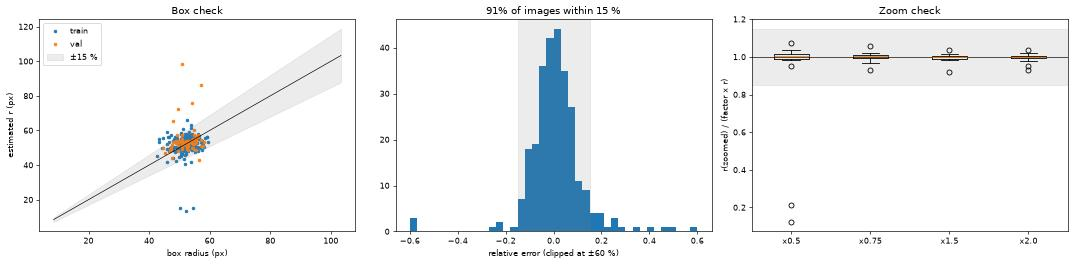

In [ ]:
zoom = pd.read_csv(TAB / "scale_zoom.csv")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for split, col in (("train", "tab:blue"), ("val", "tab:orange")):
    part = check[check["split"] == split]
    axes[0].scatter(part["r_ref"], part["r"], s=10, color=col, label=split)
lim = [check[["r", "r_ref"]].min().min() - 5, check[["r", "r_ref"]].max().max() + 5]
axes[0].plot(lim, lim, "k", lw=0.8)
axes[0].fill_between(lim, np.multiply(lim, 0.85), np.multiply(lim, 1.15), color="gray", alpha=0.15, label="±15 %")
axes[0].set_xlabel("box radius (px)")
axes[0].set_ylabel("estimated r (px)")
axes[0].legend()
axes[0].set_title("Box check")
axes[1].hist(check["rel_err"].clip(-0.6, 0.6), bins=40)
axes[1].axvspan(-0.15, 0.15, color="gray", alpha=0.15)
axes[1].set_xlabel("relative error (clipped at ±60 %)")
axes[1].set_title(f"{(check['rel_err'].abs() < 0.15).mean():.0%} of images within 15 %")
factors = sorted(zoom["zoom"].unique())
axes[2].boxplot([zoom.loc[zoom["zoom"] == f, "ratio"] for f in factors], tick_labels=[f"x{f}" for f in factors])
axes[2].axhline(1, color="k", lw=0.8)
axes[2].axhspan(0.85, 1.15, color="gray", alpha=0.15)
axes[2].set_ylabel("r(zoomed) / (factor x r)")
axes[2].set_title("Zoom check")
fig.tight_layout()
fig.savefig(FIG / "scale_validation.png", dpi=80)

box_summary = check.groupby("split")["rel_err"].agg(
    n="size", median_abs=lambda e: e.abs().median(), within_15=lambda e: (e.abs() < 0.15).mean(),
    over_30=lambda e: (e.abs() > 0.3).sum())
zoom_summary = zoom.groupby("zoom")["ratio"].agg(
    n="size", median="median", within_15=lambda x: ((x - 1).abs() < 0.15).mean())
display(box_summary, zoom_summary)

### Failure cases

The worst images (largest error). Typical causes: one large merged clump or a WBC that
dominates a field with few RBCs (over-estimate); RBC pale centres connected to the
background, so the cell looks like a thin ring (under-estimate); a very pale field where
Otsu loses the RBCs.

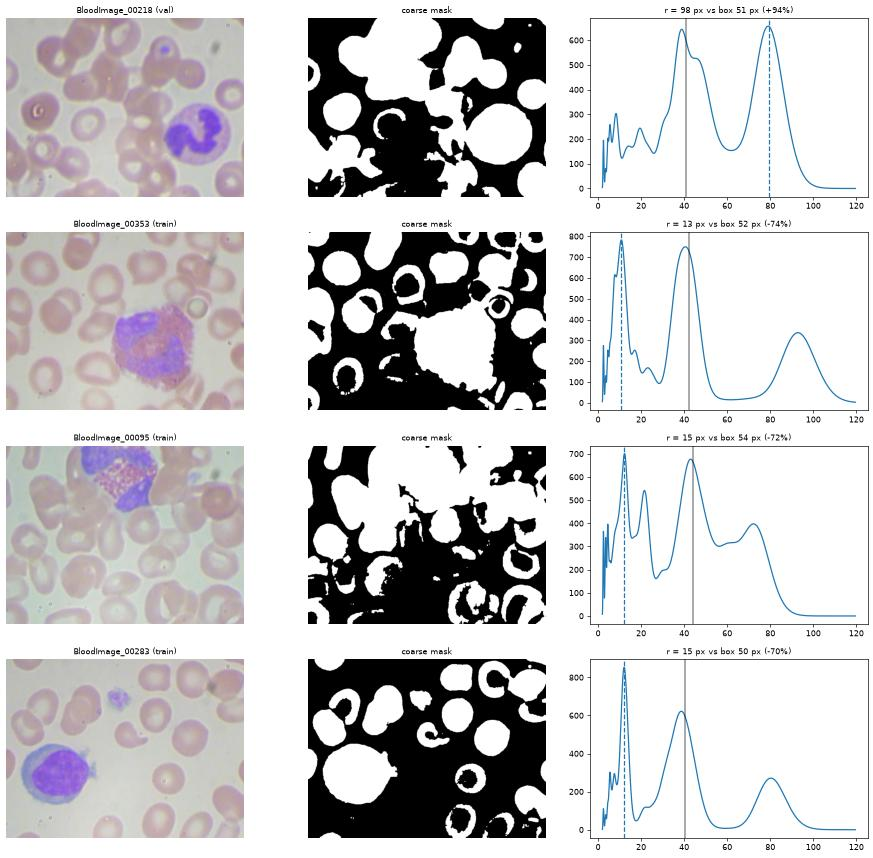

In [ ]:
worst = check.reindex(check["rel_err"].abs().sort_values(ascending=False).index).head(4)
fig, axes = plt.subplots(len(worst), 3, figsize=(15, 3.6 * len(worst)))
for row, w in zip(axes, worst.itertuples()):
    e = estimate_scale(load_image(image_path[w.image_id]), cfg)
    row[0].imshow(load_image(image_path[w.image_id]))
    row[0].set_title(f"{w.image_id} ({w.split})", fontsize=9)
    row[1].imshow(e.mask, cmap="gray")
    row[1].set_title("coarse mask", fontsize=9)
    row[2].plot(e.grid, e.density)
    row[2].axvline(e.r_inscribed, color="tab:blue", ls="--")
    row[2].axvline(w.r_ref / cfg["scale"]["calibration"], color="k", alpha=0.4, lw=2)
    row[2].set_title(f"r = {w.r:.0f} px vs box {w.r_ref:.0f} px ({w.rel_err:+.0%})", fontsize=9)
    row[0].axis("off")
    row[1].axis("off")
fig.tight_layout()
fig.savefig(FIG / "scale_failures.png", dpi=80)

## 6. Conclusions

| # | Finding | Consequence for the project |
|---|---------|-----------------------------|
| 1 | **−b\*** isolates the purple stain: background and RBCs sit around b\* ≈ 0, nuclei and platelets at b\* down to −60, independently of lightness (Fisher ratio 7.6, best of 6 channels). | `purple_channel: lab_b` kept. Thresholding −b\* (Phase 4) gives nuclei + platelets; the green channel stays the cell-vs-background channel. |
| 2 | BCCD lighting is nearly uniform: on clean images the top-hat mask agrees with plain Otsu (Dice 0.92) and the relative top-hat with the plain one (0.99). | The correction changes little on BCCD itself; its effect is measured in the Phase 9 ablation. |
| 3 | Under synthetic **vignetting** (strength 0.4) plain Otsu drops to Dice 0.79 (min 0.70); the black top-hat to 0.87 but **collapses on one image (0.34)**: Otsu then splits RBC vs WBC because the dim corners also lose contrast; the **relative top-hat** (closing − image) / closing stays at 0.96 (min 0.90). | `tophat_relative: true` (flat-field correction: transmitted light is illumination × transmittance). Unit test `test_relative_tophat_corrects_multiplicative_vignetting`. |
| 4 | The **raw area-weighted pattern spectrum** is spiky and dominated by one WBC or clump: only 35 % of val images within 15 % of the box radius. Weighting by 1/ρ and smoothing in log-radius (σ = 0.08) gives **90 %** (median error 3.7 %). | `scale.weight: 1`, `scale.sigma_log: 0.08`. A pure count weighting (1/ρ²) lets debris win. |
| 5 | The spectrum peak is the **inscribed** radius; the box radius is **1.24 ×** larger (oval cells, missed pale rim, contact). | `scale.calibration: 1.24`, fitted on train only (`make scale-check`, `--update-config` to refit); val agrees (same error with the fitted or the config value). |
| 6 | **Zoom check**: rescaling the image by 0.5 / 0.75 / 1.5 / 2 multiplies r by the same factor (median ratio 0.997–1.007; 100 % within 15 % except 2 / 30 images at ×0.5). | `r` adapts to the magnification: all size parameters in units of r are scale-free. Note that the box check alone cannot show this: a constant 52 px scores 99 % on BCCD (single magnification). |
| 7 | Remaining failures (5 / 74 val, > 30 %): rings whose pale centre touches the background (under-estimate, e.g. 00283), large merged clumps or a WBC dominating a sparse field, very pale RBCs lost by Otsu (over-estimate). | `r_default` fallback rarely triggers (0 images): the failures are confident wrong peaks. Phase 4 can re-estimate `r` on the clean mask (shape-filtered hole fill) if needed; the per-image errors are in `results/tables/scale_check.csv`. |